In [ ]:
from pathlib import Path

import marimo as mo

from poc_lottery_randomness_auditor import charts, theme
from poc_lottery_randomness_auditor.data import load_draws
from poc_lottery_randomness_auditor.engine import power as power_engine
from poc_lottery_randomness_auditor.engine.battery import run_battery
from poc_lottery_randomness_auditor.games import LOTTO

theme.register_theme()
seed = 20261021
battery_replicates = 500
power_replicates = 200
draws = load_draws(Path("data/snapshots/lotto"), LOTTO)
battery = run_battery(draws, LOTTO, seed=seed, replicates=battery_replicates)
power_by_era = {
    era.name: power_engine.power_grid(
        power_engine.DEFAULT_SCENARIOS,
        era,
        power_replicates,
        seed,
    )
    for era in LOTTO.eras
    if (draws["era"] == era.name).any()
}
mo.md("Snapshot, battery and power grid loaded.")

<span class="markdown prose dark:prose-invert contents"><span class="paragraph">Snapshot, battery and power grid loaded.</span></span>

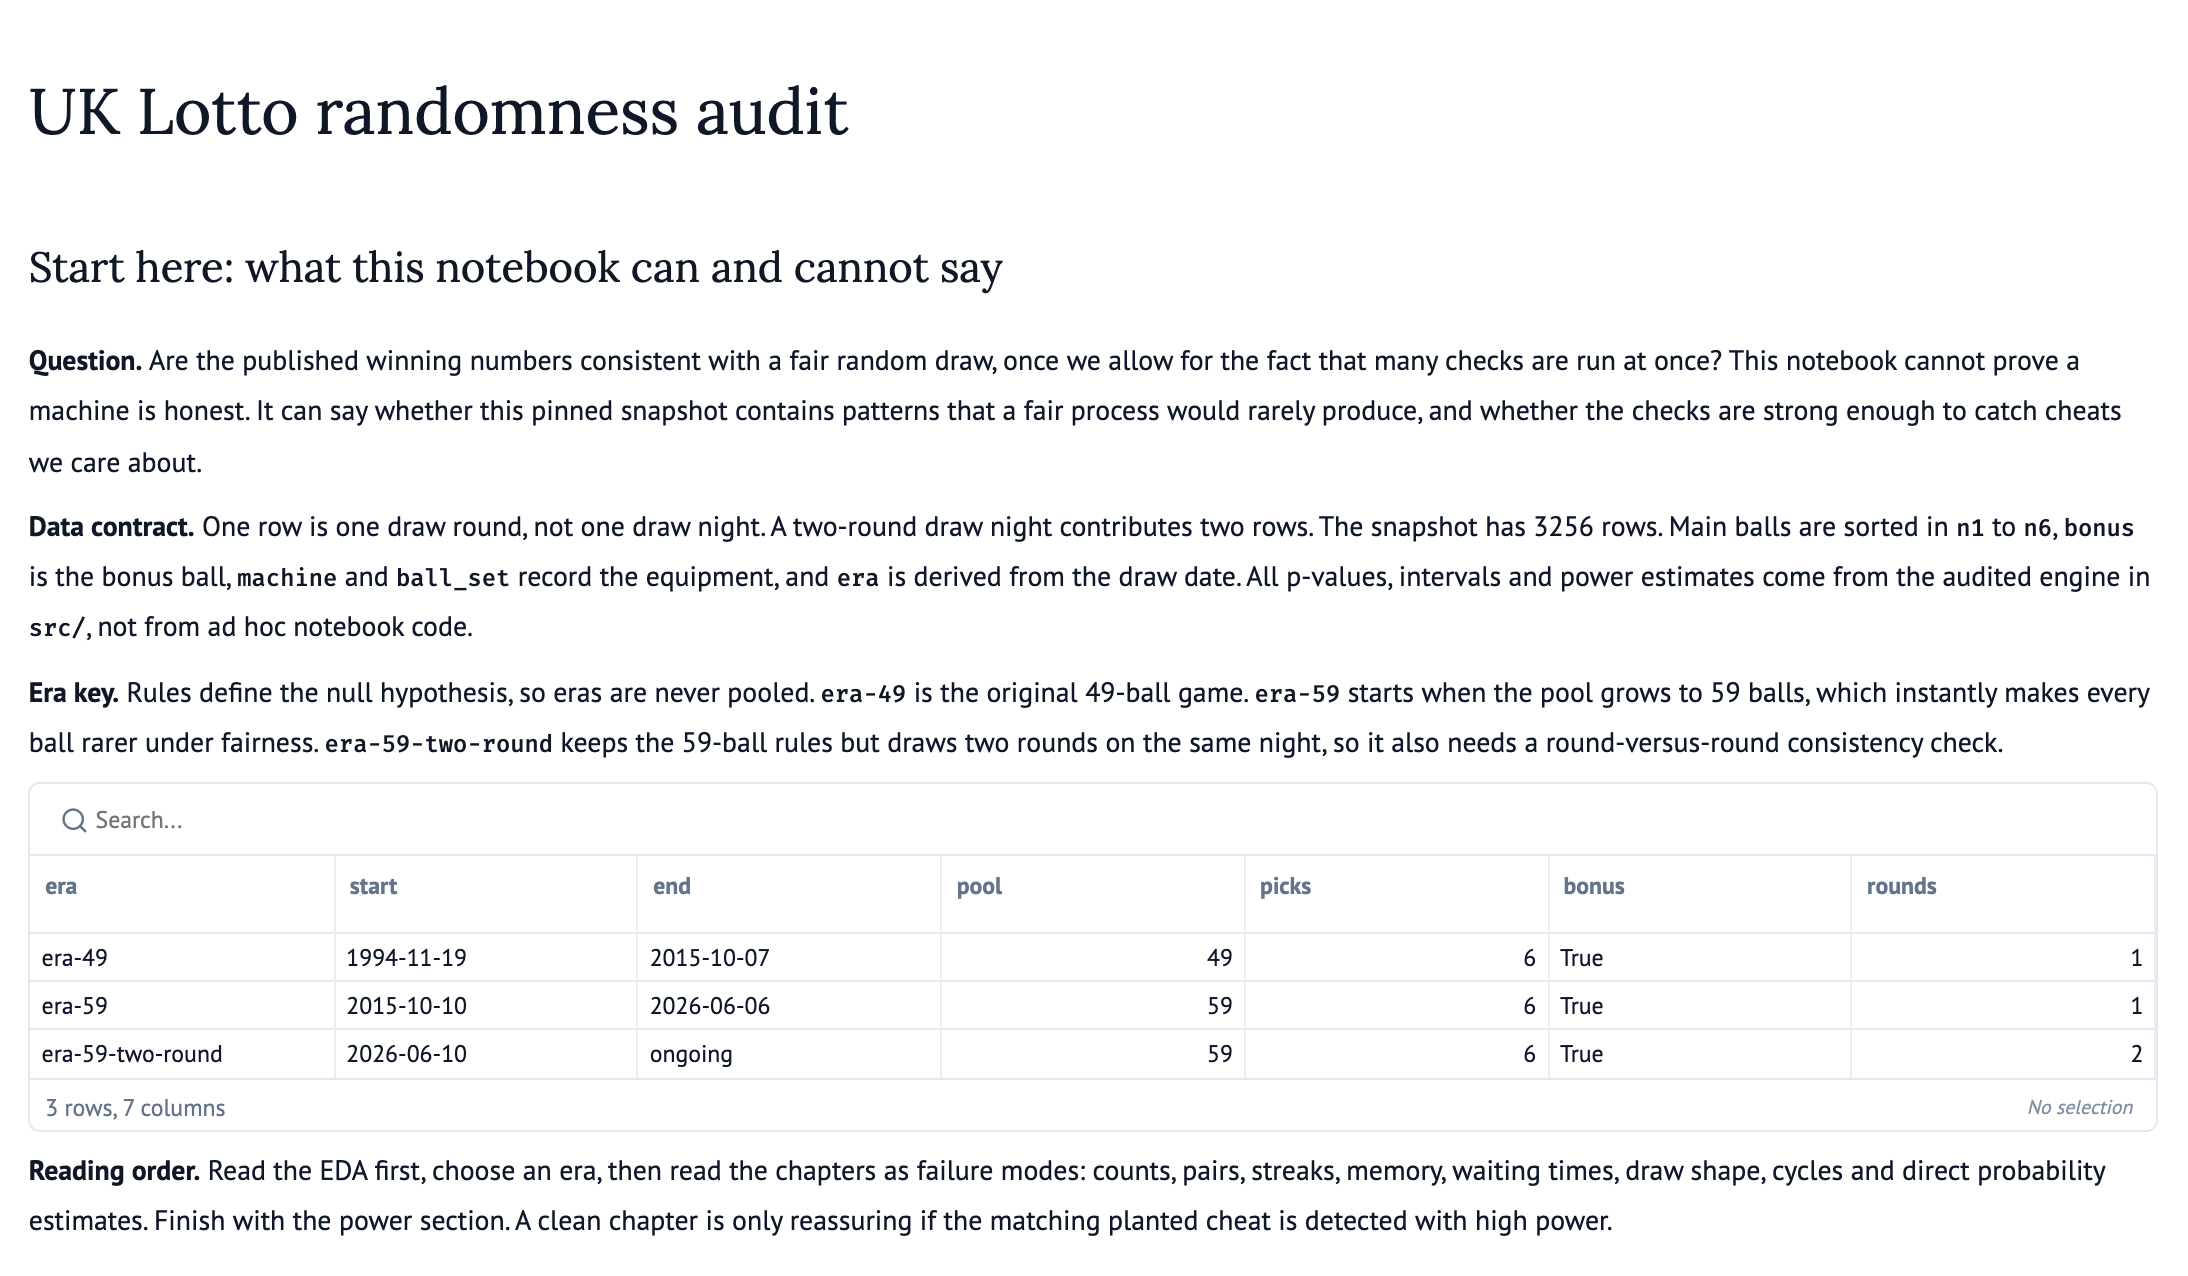

In [ ]:
era_rows = [
    {
        "era": era.name,
        "start": era.start.isoformat(),
        "end": era.end.isoformat() if era.end else "ongoing",
        "pool": era.pool_size,
        "picks": era.picks,
        "bonus": era.has_bonus,
        "rounds": era.rounds_per_draw,
    }
    for era in LOTTO.eras
]
mo.vstack(
    [
        mo.md("# UK Lotto randomness audit"),
        mo.md("## Start here: what this notebook can and cannot say"),
        mo.md(
            """
            **Question.** Are the published winning numbers consistent with a
            fair random draw, once we allow for the fact that many checks are
            run at once? This notebook cannot prove a machine is honest. It
            can say whether this pinned snapshot contains patterns that a
            fair process would rarely produce, and whether the checks are
            strong enough to catch cheats we care about.
            """
        ),
        mo.md(
            f"""
            **Data contract.** One row is one draw round, not one draw night.
            A two-round draw night contributes two rows. The snapshot has
            {len(draws)} rows. Main balls are sorted in `n1` to `n6`,
            `bonus` is the bonus ball, `machine` and `ball_set` record the
            equipment, and `era` is derived from the draw date. All p-values,
            intervals and power estimates come from the audited engine in
            `src/`, not from ad hoc notebook code.
            """
        ),
        mo.md(
            """
            **Era key.** Rules define the null hypothesis, so eras are never
            pooled. `era-49` is the original 49-ball game. `era-59` starts
            when the pool grows to 59 balls, which instantly makes every ball
            rarer under fairness. `era-59-two-round` keeps the 59-ball rules
            but draws two rounds on the same night, so it also needs a
            round-versus-round consistency check.
            """
        ),
        mo.ui.table(era_rows, pagination=False, selection=None),
        mo.md(
            """
            **Reading order.** Read the EDA first, choose an era, then read
            the chapters as failure modes: counts, pairs, streaks, memory,
            waiting times, draw shape, cycles and direct probability
            estimates. Finish with the power section. A clean chapter is only
            reassuring if the matching planted cheat is detected with high
            power.
            """
        ),
    ]
)

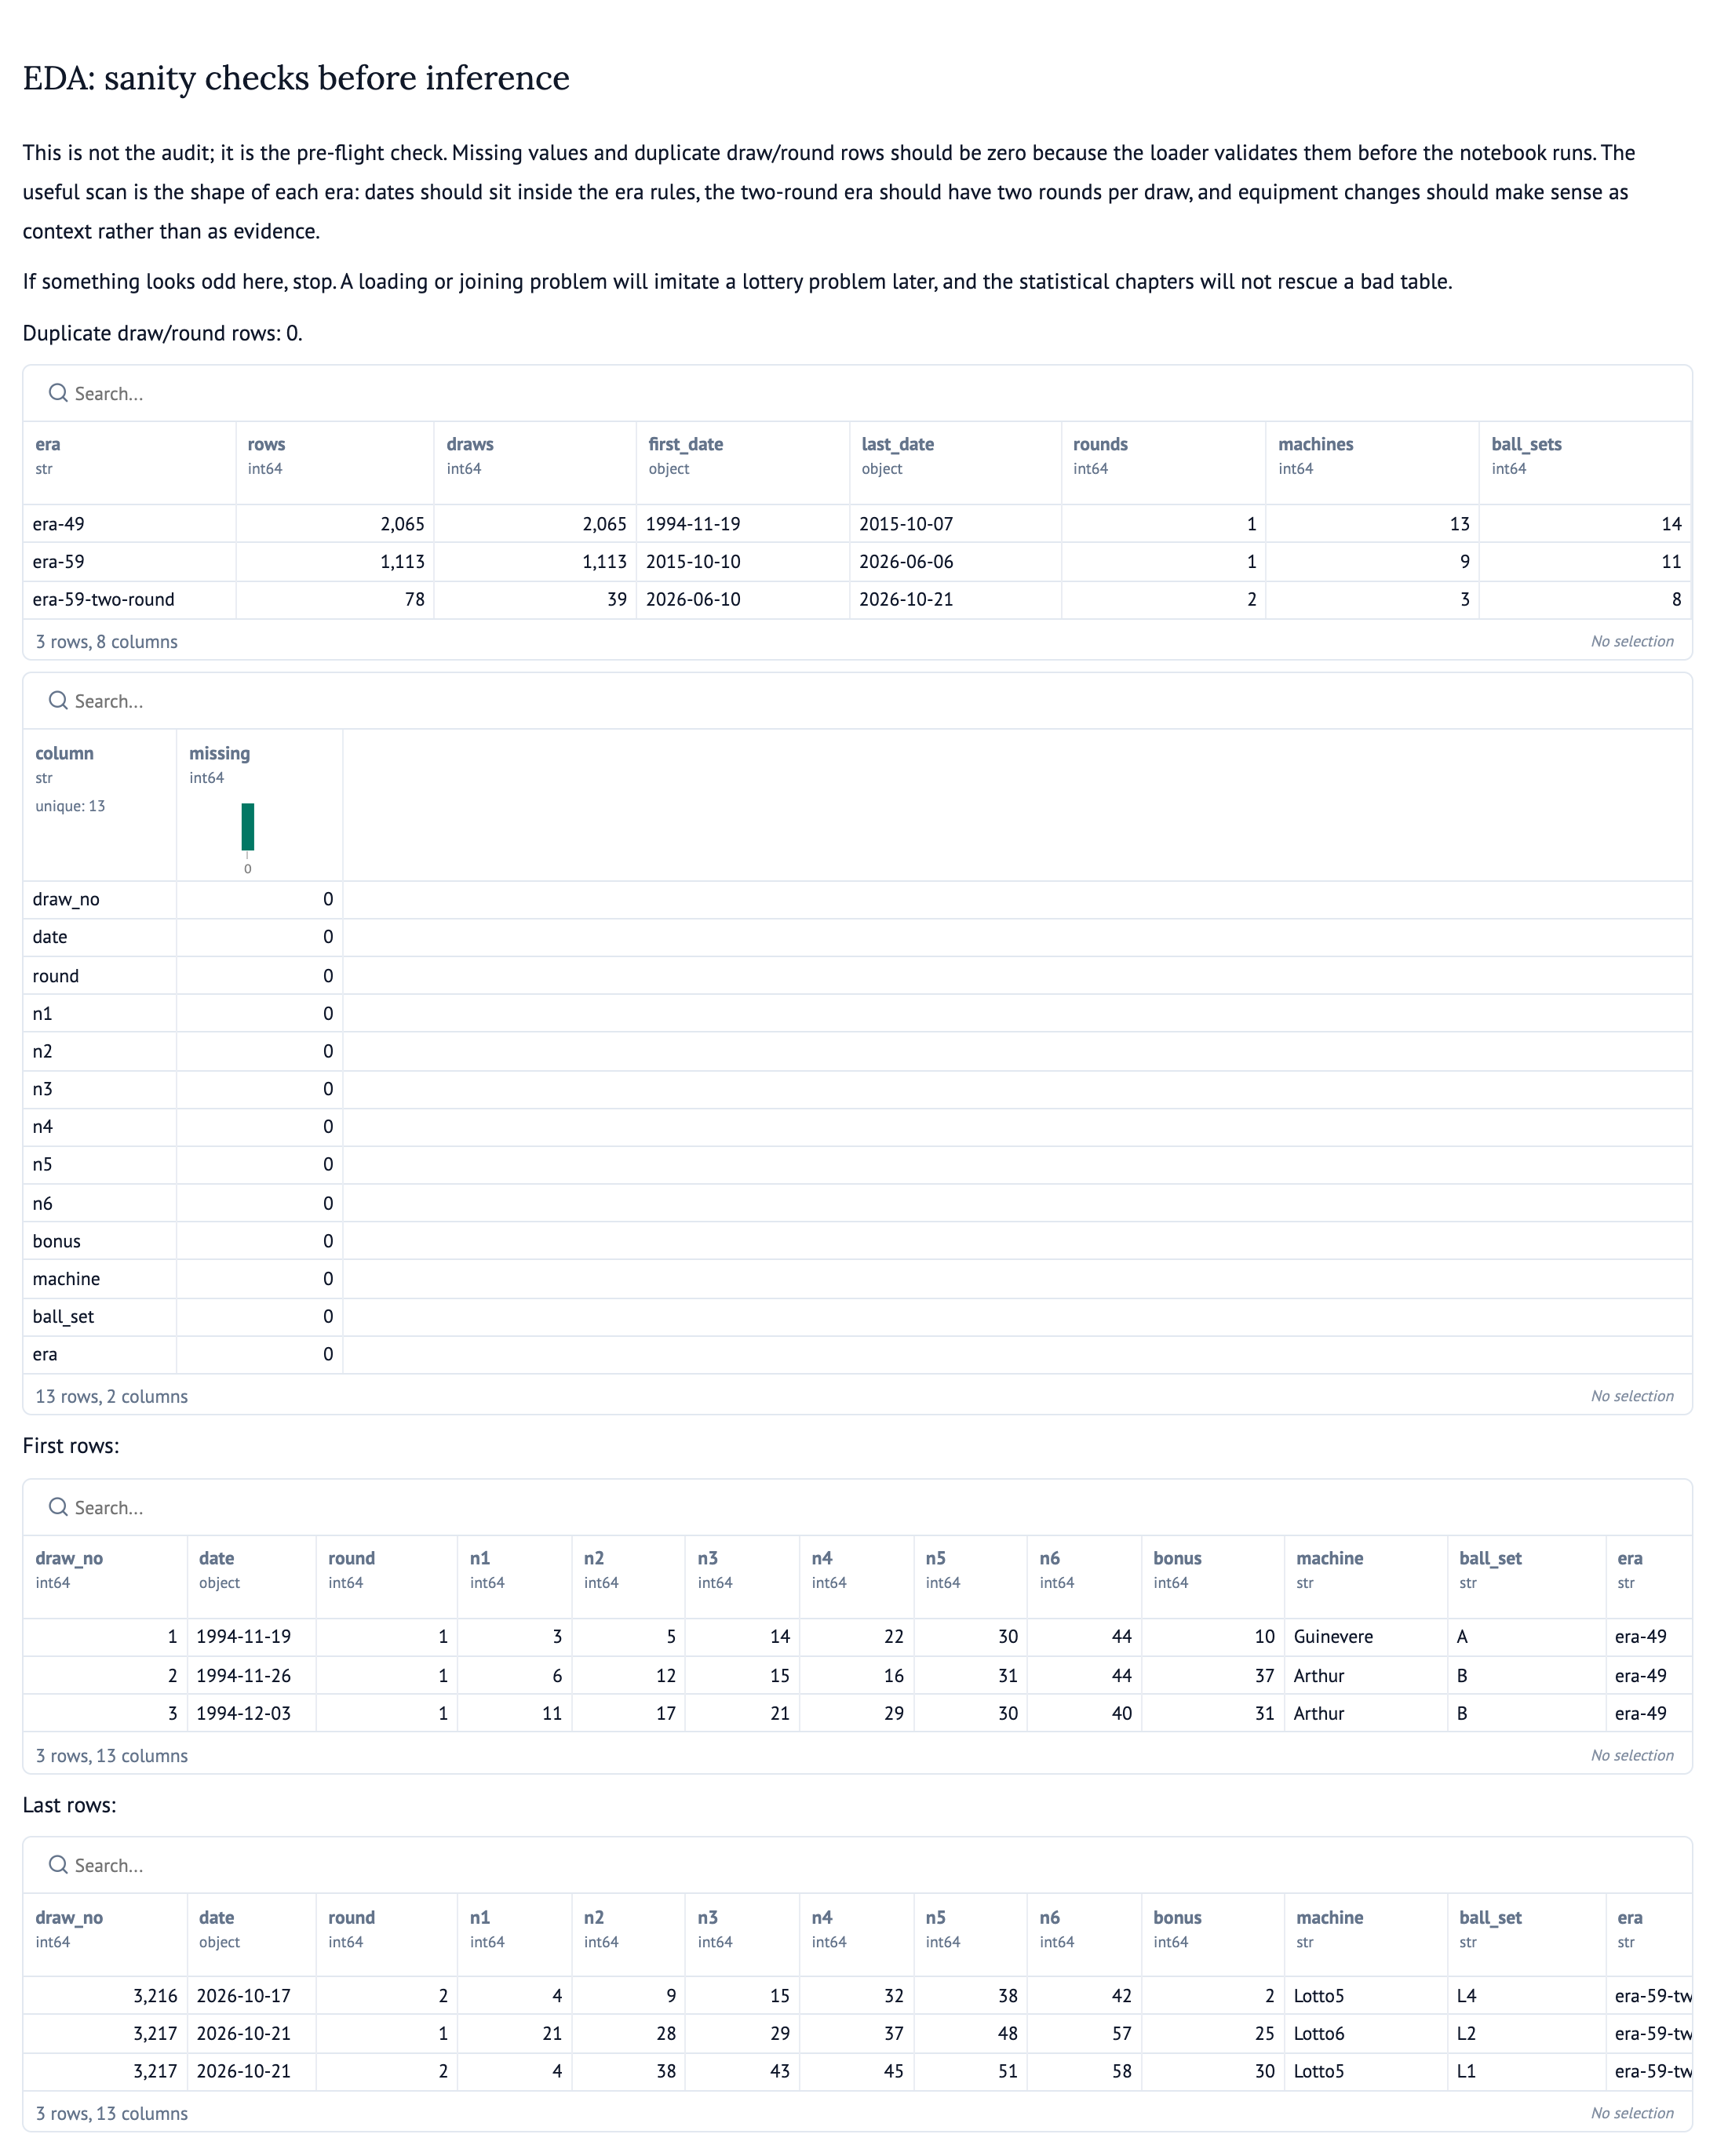

In [ ]:
overview = (
    draws.groupby("era", observed=True)
    .agg(
        rows=("draw_no", "size"),
        draws=("draw_no", "nunique"),
        first_date=("date", "min"),
        last_date=("date", "max"),
        rounds=("round", "nunique"),
        machines=("machine", "nunique"),
        ball_sets=("ball_set", "nunique"),
    )
    .reset_index()
)
missing = (
    draws.isna()
    .sum()
    .rename("missing")
    .reset_index()
    .rename(columns={"index": "column"})
)
duplicate_rounds = int(draws.duplicated(["draw_no", "round"]).sum())
mo.vstack(
    [
        mo.md("## EDA: sanity checks before inference"),
        mo.md(
            """
            This is not the audit; it is the pre-flight check. Missing values
            and duplicate draw/round rows should be zero because the loader
            validates them before the notebook runs. The useful scan is the
            shape of each era: dates should sit inside the era rules, the
            two-round era should have two rounds per draw, and equipment
            changes should make sense as context rather than as evidence.
            """
        ),
        mo.md(
            """
            If something looks odd here, stop. A loading or joining problem
            will imitate a lottery problem later, and the statistical
            chapters will not rescue a bad table.
            """
        ),
        mo.md(f"Duplicate draw/round rows: {duplicate_rounds}."),
        mo.ui.table(overview, pagination=False, selection=None),
        mo.ui.table(missing, pagination=False, selection=None),
        mo.md("First rows:"),
        mo.ui.table(draws.head(3), pagination=False, selection=None),
        mo.md("Last rows:"),
        mo.ui.table(draws.tail(3), pagination=False, selection=None),
    ]
)

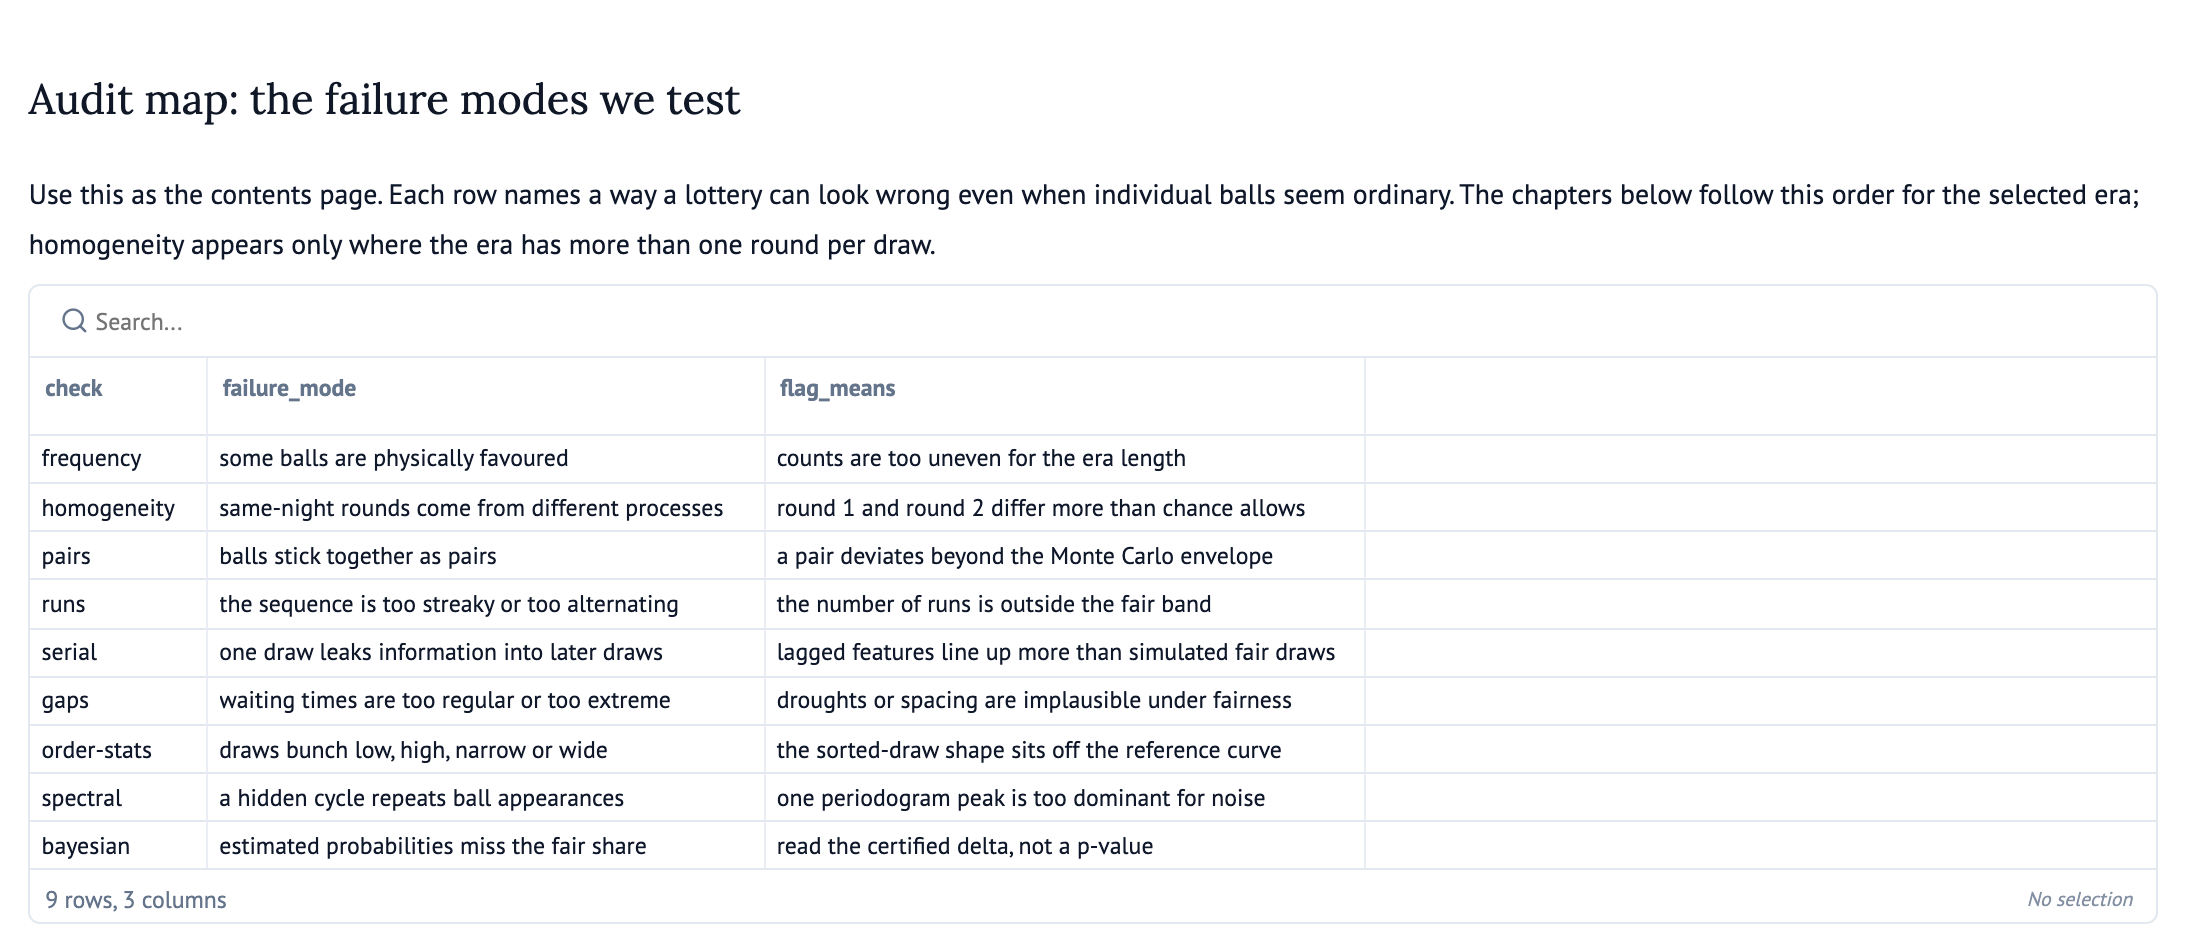

In [ ]:
audit_map = [
    {
        "check": "frequency",
        "failure_mode": "some balls are physically favoured",
        "flag_means": "counts are too uneven for the era length",
    },
    {
        "check": "homogeneity",
        "failure_mode": "same-night rounds come from different processes",
        "flag_means": "round 1 and round 2 differ more than chance allows",
    },
    {
        "check": "pairs",
        "failure_mode": "balls stick together as pairs",
        "flag_means": "a pair deviates beyond the Monte Carlo envelope",
    },
    {
        "check": "runs",
        "failure_mode": "the sequence is too streaky or too alternating",
        "flag_means": "the number of runs is outside the fair band",
    },
    {
        "check": "serial",
        "failure_mode": "one draw leaks information into later draws",
        "flag_means": "lagged features line up more than simulated fair draws",
    },
    {
        "check": "gaps",
        "failure_mode": "waiting times are too regular or too extreme",
        "flag_means": "droughts or spacing are implausible under fairness",
    },
    {
        "check": "order-stats",
        "failure_mode": "draws bunch low, high, narrow or wide",
        "flag_means": "the sorted-draw shape sits off the reference curve",
    },
    {
        "check": "spectral",
        "failure_mode": "a hidden cycle repeats ball appearances",
        "flag_means": "one periodogram peak is too dominant for noise",
    },
    {
        "check": "bayesian",
        "failure_mode": "estimated probabilities miss the fair share",
        "flag_means": "read the certified delta, not a p-value",
    },
]
mo.vstack(
    [
        mo.md("## Audit map: the failure modes we test"),
        mo.md(
            "Use this as the contents page. Each row names a way a lottery "
            "can look wrong even when individual balls seem ordinary. The "
            "chapters below follow this order for the selected era; "
            "homogeneity appears only where the era has more than one round "
            "per draw."
        ),
        mo.ui.table(audit_map, pagination=False, selection=None),
    ]
)

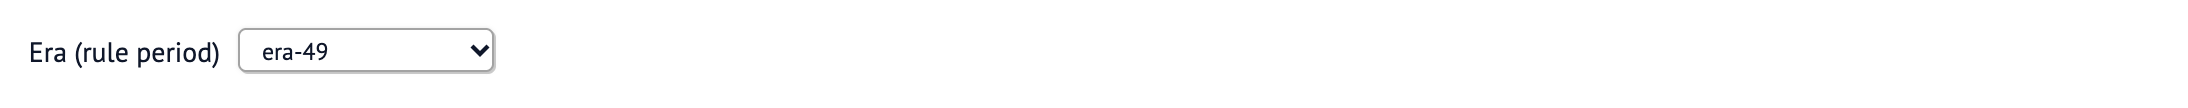

In [ ]:
era_selector = mo.ui.dropdown(
    options=[era.name for era in LOTTO.eras],
    value="era-59",
    label="Era (rule period)",
)
era_selector

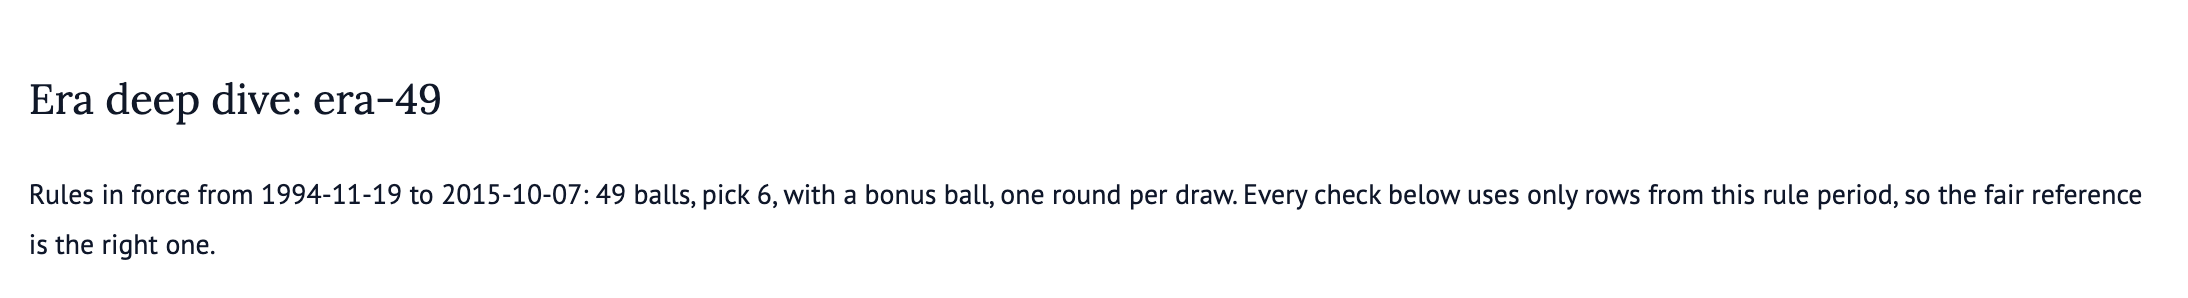

In [ ]:
era_name = era_selector.value
era = next(era for era in LOTTO.eras if era.name == era_name)
end = era.end.isoformat() if era.end else "ongoing"
rounds = (
    "one round" if era.rounds_per_draw == 1 else f"{era.rounds_per_draw} rounds"
)
bonus = "with a bonus ball" if era.has_bonus else "with no bonus ball"
by_key = {
    (result.family, result.subject): result
    for result in battery.results
    if result.era == era_name
}
mo.vstack(
    [
        mo.md(f"## Era deep dive: {era_name}"),
        mo.md(
            f"Rules in force from {era.start.isoformat()} to {end}: "
            f"{era.pool_size} balls, pick {era.picks}, {bonus}, {rounds} "
            "per draw. Every check below uses only rows from this rule "
            "period, so the fair reference is the right one."
        ),
    ]
)

In [ ]:
rejections = set(battery.rejections_bh)

def verdict(result):
    if result is None:
        return "This check was not run for the selected era."
    key = f"{result.era}:{result.family}:{result.subject}"
    if key in rejections:
        return (
            "Needs follow-up. A fair lottery would rarely produce a result "
            "this odd, and it remains unusual after allowing for the number "
            "of checks. A statistician should inspect the raw draws and "
            "machine context before any conclusion."
        )
    if result.p_value is None:
        return (
            "Read the certified delta below. This is a direct probability "
            "estimate, not a pass/fail p-value."
        )
    share = result.p_value * 100
    if result.p_value >= 0.5:
        return (
            "No follow-up needed. Fair lotteries produce a result at least "
            f"this odd in most similar histories (about {share:.0f}%), so "
            "this sits inside ordinary variation."
        )
    if result.p_value >= 0.05:
        return (
            "No follow-up needed. Fair lotteries produce a result at least "
            f"this odd in about {share:.1f}% of similar histories, which "
            "is still plausible once the number of checks is counted."
        )
    return (
        "Rare, but not proof on its own. Fair lotteries produce a result "
        f"at least this odd in only about {share:.2f}% of similar histories."
    )

mo.md("")

<span class="markdown prose dark:prose-invert contents"></span>



In [ ]:
def chapter(title, family, subject, why, fair, worry, maths):
    result = by_key.get((family, subject))
    blocks = [
        mo.md(f"## {title}"),
        mo.md(f"**Why this matters.** {why}"),
        mo.md(f"**What fair looks like.** {fair}"),
        mo.md(f"**What would worry me.** {worry}"),
    ]
    if result is not None and family in charts.CHARTS_BY_FAMILY:
        blocks.append(charts.CHARTS_BY_FAMILY[family](result))
    blocks.append(
        mo.callout(mo.md(maths), kind="info", title="Maths, for reference")
    )
    blocks.append(mo.md(f"**Verdict.** {verdict(result)}"))
    return mo.vstack(blocks)

bonus_verdict = verdict(by_key.get(("frequency", "bonus")))
runs_high_verdict = verdict(by_key.get(("runs", "sum-high")))
homogeneity_main = verdict(by_key.get(("homogeneity", "main-round1-vs-round2")))
homogeneity_bonus = verdict(by_key.get(("homogeneity", "bonus-round1-vs-round2")))

mo.vstack(
    [
        chapter(
            "Are any balls drawn too often, or not often enough?",
            "frequency",
            "main",
            "A worn ball, biased set or bad mixing step can favour some "
            "numbers before any fancier pattern shows up.",
            "Every bar should sit close to the fair share. With dozens of "
            "balls, a few percent high or low is ordinary scatter.",
            "One or two balls far outside the pack, especially the same "
            "balls in more than one era.",
            "For counts $c_i$ over $N$ balls, the statistic is $\\sum_i "
            "(c_i - N/6)^2 / (N/6)$, compared with a chi-square reference.",
        ),
        mo.md(f"**Bonus ball.** {bonus_verdict}"),
        chapter(
            "Do same-night rounds come from the same process?",
            "homogeneity",
            "main-round1-vs-round2",
            "In the two-round era, round 1 and round 2 should be exchangeable. "
            "If they differ, the problem may be procedural rather than a "
            "single biased ball.",
            "The two count vectors should look like two samples from one "
            "multinomial draw.",
            "A systematic shift between rounds, not a one-night blip.",
            "Two count vectors are compared in a 2 by 59 contingency table; "
            "categories never seen in either round are dropped before the "
            "chi-square test.",
        ),
        mo.md(f"**Main balls.** {homogeneity_main}"),
        mo.md(f"**Bonus balls.** {homogeneity_bonus}"),
        chapter(
            "Are any ball pairs suspiciously sticky or avoidant?",
            "pairs",
            "main",
            "Every ball can look fair on its own while two balls travel "
            "together too often or almost never appear together.",
            "The pair map should be mostly flat. Hundreds of pairs are "
            "checked, so a few moderate hotspots are expected.",
            "The same pair standing out repeatedly, or a cluster of balls "
            "whose pairs all lean the same way.",
            "All 1,711 unordered pairs are compared with the fair pair "
            "count and summarised by one max-deviation statistic against a "
            "Monte Carlo null.",
        ),
        chapter(
            "Is the sequence of draw sums too streaky or too regular?",
            "runs",
            "sum-parity",
            "A fair draw has no memory, so the sequence should not settle "
            "into long streaks or metronomic alternation.",
            "Runs happen, but their count should match permutations of the "
            "same sequence.",
            "Far fewer runs than expected, which suggests cycling, or far "
            "more, which suggests over-correction.",
            "The number of runs is converted to a z-score and compared "
            "with permutations of the same bit sequence.",
        ),
        mo.md(f"**High-sum sequence.** {runs_high_verdict}"),
        chapter(
            "Does one draw leak information into the next?",
            "serial",
            "main-features",
            "If last week's draw helps predict this week's draw, the "
            "process is not the independent draw the rules assume.",
            "Autocorrelation at short lags should sit inside the spread "
            "seen in fair simulated histories.",
            "A stable lag pattern across the era, not one odd lag in a "
            "short stretch.",
            "For each feature, the autocorrelation at lags 1 to 10 is "
            "compared with the spread seen in fair simulated histories.",
        ),
        chapter(
            "Are the waiting times between appearances believable?",
            "gaps",
            "main",
            "For each ball, droughts and clusters should follow the "
            "geometric waiting-time pattern implied by the era rules.",
            "Short gaps are common, long gaps are rare, and very long gaps "
            "still happen sometimes.",
            "Spacing that is too regular, or droughts and clusters outside "
            "the fair band for several balls at once.",
            "Each ball's empirical gap distribution is compared with the "
            "geometric reference by a Kolmogorov-Smirnov distance.",
        ),
        chapter(
            "Do the smallest, largest and spread of balls look right?",
            "order-stats",
            "main",
            "Even when individual counts look fine, draws could bunch low, "
            "high, narrow or wide.",
            "The empirical curves for minimum, maximum and range should "
            "track the exact fair reference curves.",
            "A curve that leaves the reference band over a broad range "
            "rather than wiggling at one end.",
            "Empirical CDFs for the minimum, maximum and range are "
            "compared with the exact order-statistic reference CDFs.",
        ),
        chapter(
            "Is there a hidden cycle in when balls appear?",
            "spectral",
            "main",
            "A mechanical or procedural fault could make a ball appear with "
            "a fixed period even if its overall count is almost fair.",
            "No frequency should dominate; the largest peaks should look "
            "like the background noise of a fair sequence.",
            "A sharp peak at the same cycle for several balls, or a peak "
            "that survives when the era is split in half.",
            "A periodogram is computed for each ball and the largest "
            "peak-to-median ratio is compared with fair simulated draws.",
        ),
        chapter(
            "How far are the estimated ball probabilities from fair?",
            "bayesian",
            "main",
            "This chapter answers the practical question directly: after "
            "seeing this era, how large could each ball's probability "
            "plausibly be?",
            "Intervals should cover or straddle the fair share; wider "
            "intervals mean a short era, not a failed lottery.",
            "Several intervals clearing the same side of the fair line, "
            "which is much harder to explain than one narrow miss.",
            "A Dirichlet(1) prior gives Beta marginal posteriors; the "
            "certified delta is the smallest band containing every 95% "
            "interval around the fair share.",
        ),
    ]
)

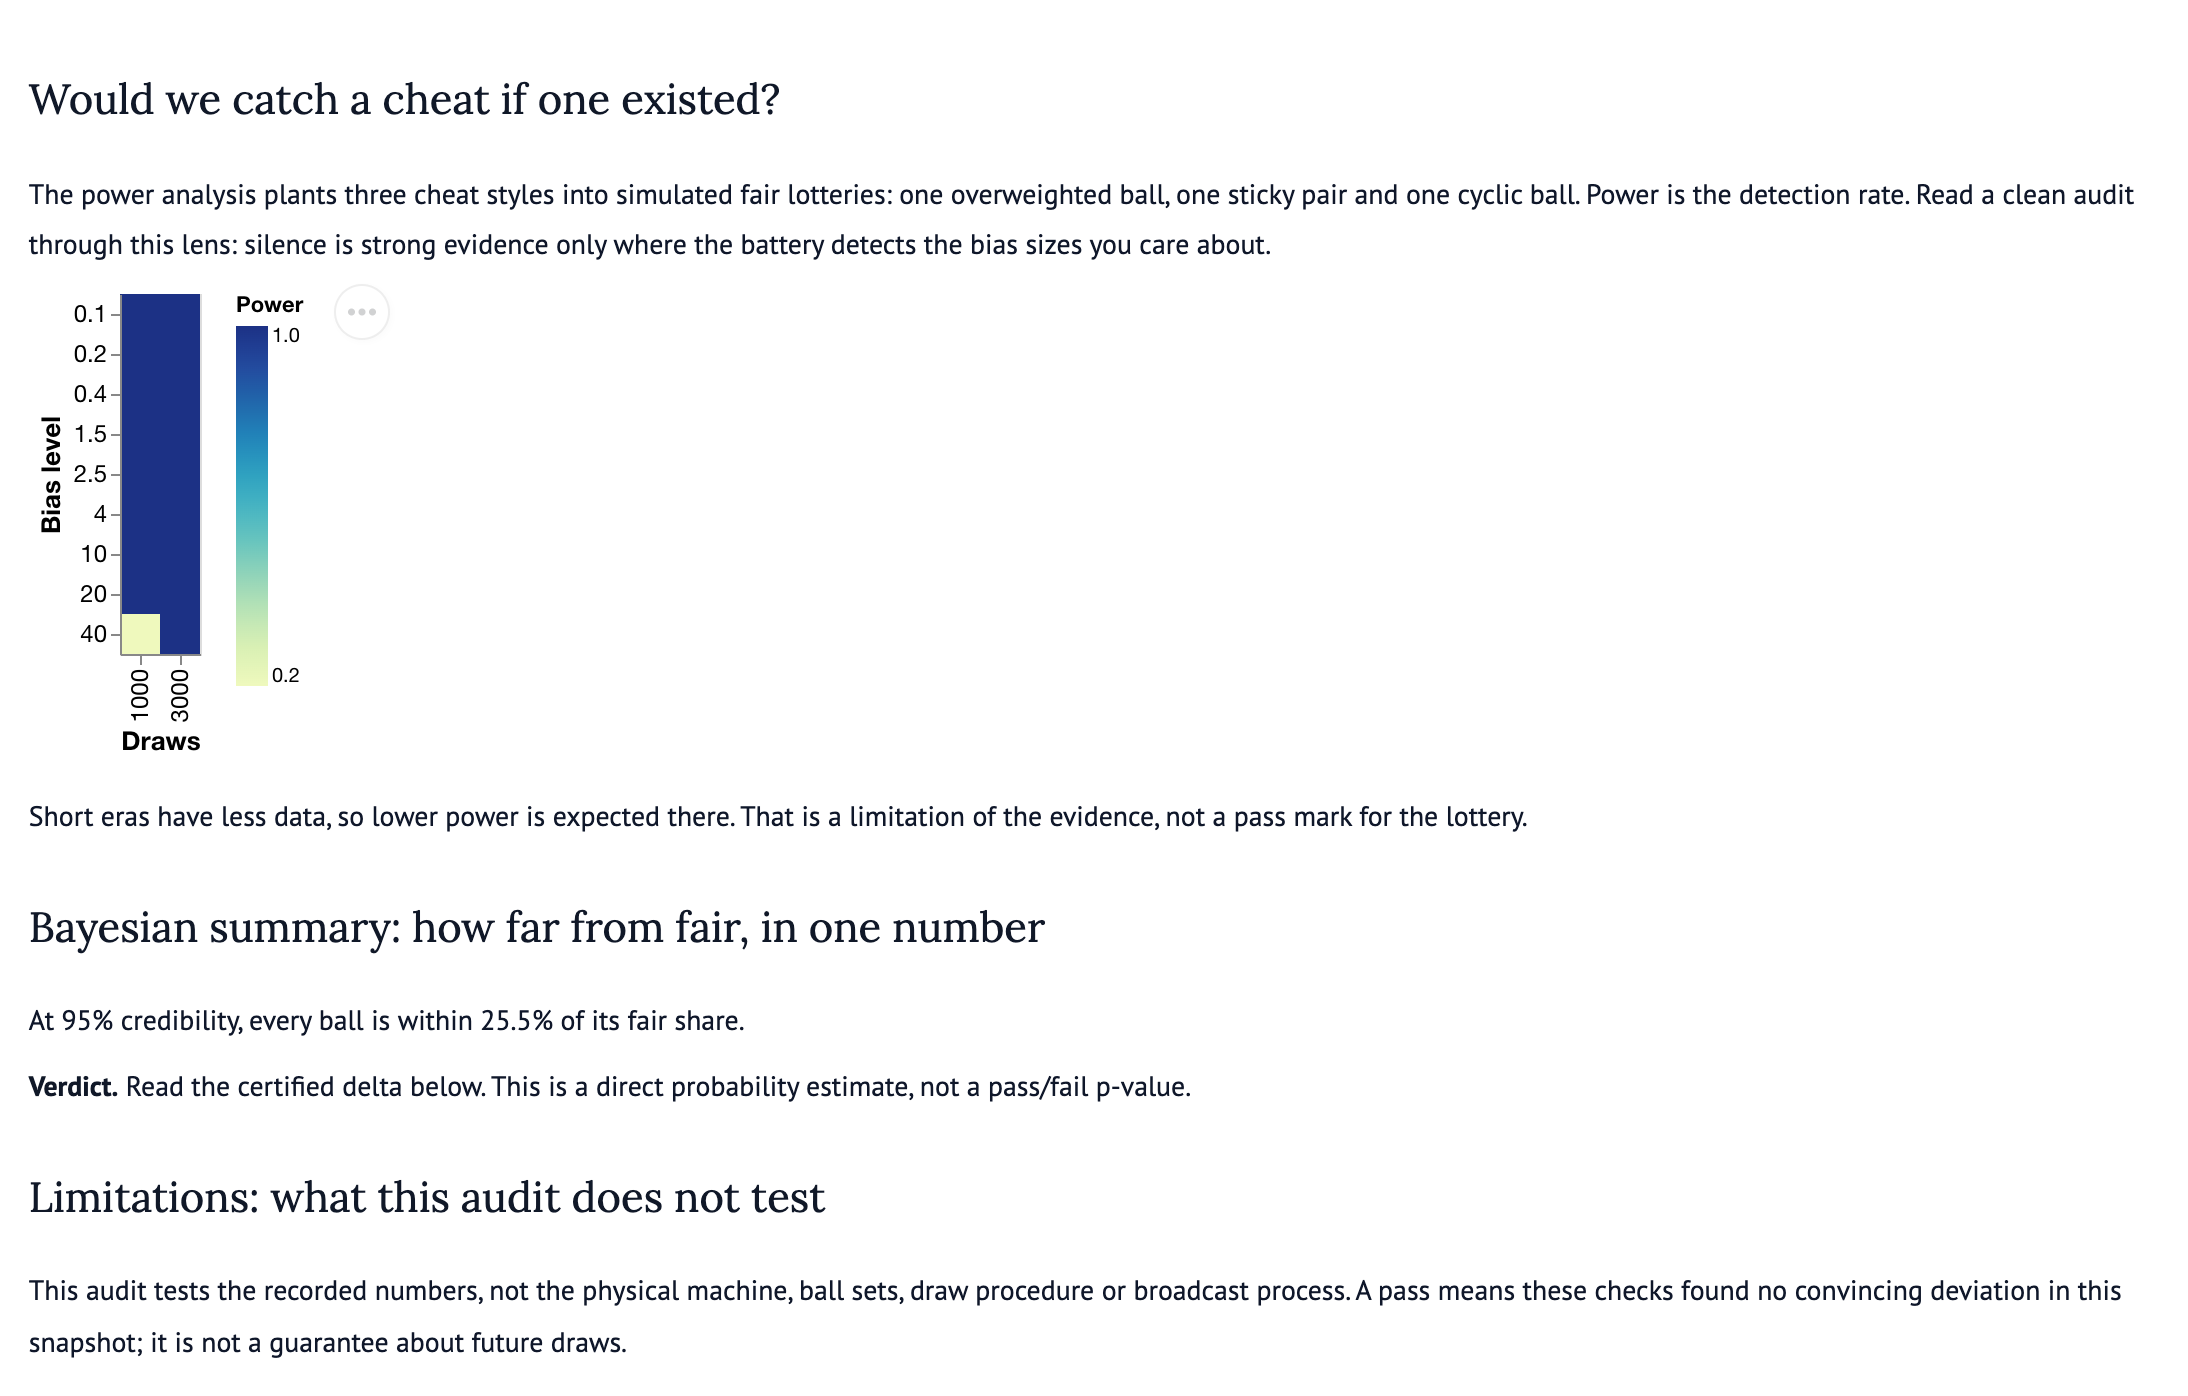

In [ ]:
bayesian = by_key.get(("bayesian", "main"))
certified = (
    f"At 95% credibility, every ball is within {bayesian.statistic:.1%} of its fair share."
    if bayesian is not None
    else "No Bayesian result was run for this era."
)
power_frame = power_by_era.get(era_name)
power_chart = (
    charts.power_chart(power_frame)
    if power_frame is not None
    else mo.md("No power grid for this era.")
)
mo.vstack(
    [
        mo.md("## Would we catch a cheat if one existed?"),
        mo.md(
            "The power analysis plants three cheat styles into simulated "
            "fair lotteries: one overweighted ball, one sticky pair and one "
            "cyclic ball. Power is the detection rate. Read a clean audit "
            "through this lens: silence is strong evidence only where the "
            "battery detects the bias sizes you care about."
        ),
        power_chart,
        mo.md(
            "Short eras have less data, so lower power is expected there. "
            "That is a limitation of the evidence, not a pass mark for the "
            "lottery."
        ),
        mo.md("## Bayesian summary: how far from fair, in one number"),
        mo.md(certified),
        mo.md(f"**Verdict.** {verdict(bayesian)}"),
        mo.md("## Limitations: what this audit does not test"),
        mo.md(
            "This audit tests the recorded numbers, not the physical "
            "machine, ball sets, draw procedure or broadcast process. A "
            "pass means these checks found no convincing deviation in this "
            "snapshot; it is not a guarantee about future draws."
        ),
    ]
)